In [1]:
import os
import pandas as pd

if not os.path.exists('dataset_sms_spam_v1.csv'):
  from google.colab import files
  files.upload()

df = pd.read_csv('dataset_sms_spam_v1.csv')
print(df.isnull().sum())

Saving dataset_sms_spam_v1.csv to dataset_sms_spam_v1.csv
teks     0
label    0
dtype: int64


In [2]:
print('duplikat awal:', df.duplicated().sum())
df = df.dropna(subset=['teks', 'label']).copy()
df['teks'] = df['teks'].astype(str).str.lower().str.strip()
df['label'] = df['label'].astype(int)
df = df.drop_duplicates(subset='teks')
print('Total data bersih:', len(df))

duplikat awal: 1
Total data bersih: 1142


In [3]:
kelas = ['Normal', 'Penipuan', 'promo']
distribusi = df['label'].value_counts().sort_index()
print(pd.DataFrame({'Kategori': kelas, 'Jumlah': distribusi.values}))

   Kategori  Jumlah
0    Normal     568
1  Penipuan     335
2     promo     239


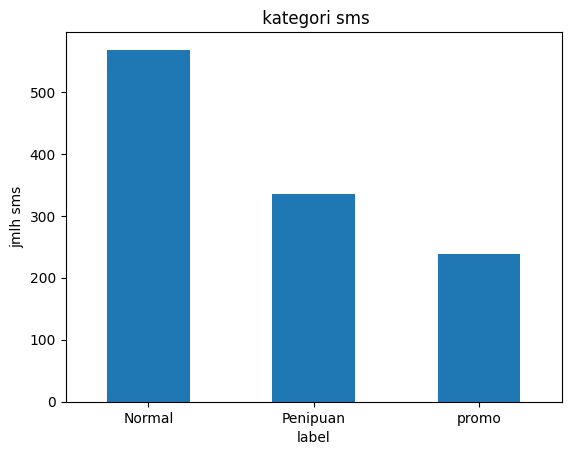

latihan : 913 | uji: 229

Naive Bayes [0.908 0.86  0.925 0.939 0.904] Rata-Rata 0.9072
Akurasi: 0.9214
              precision    recall  f1-score   support

      Normal       0.94      0.98      0.96       114
    Penipuan       0.92      0.88      0.90        67
       promo       0.87      0.83      0.85        48

    accuracy                           0.92       229
   macro avg       0.91      0.90      0.90       229
weighted avg       0.92      0.92      0.92       229



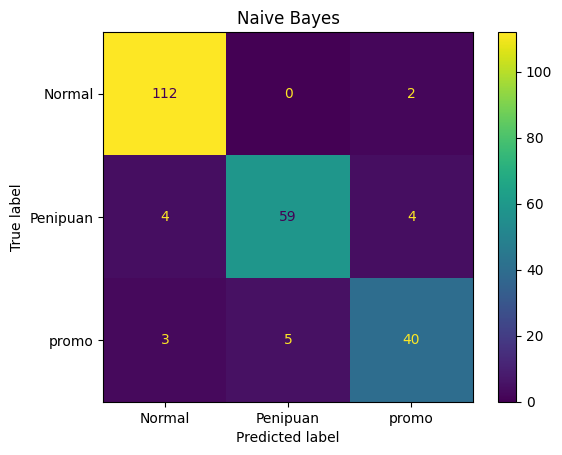

Akurasi latih: 0.9956
Akurasi uji  : 0.9214

--------------------------------------------------

Logistic Regression [0.891 0.834 0.943 0.943 0.912] Rata-Rata 0.9046
Akurasi: 0.917
              precision    recall  f1-score   support

      Normal       0.94      0.98      0.96       114
    Penipuan       0.91      0.88      0.89        67
       promo       0.87      0.81      0.84        48

    accuracy                           0.92       229
   macro avg       0.91      0.89      0.90       229
weighted avg       0.92      0.92      0.92       229



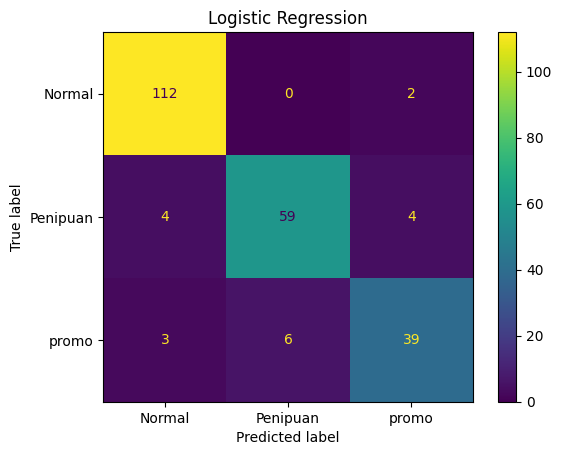

Akurasi latih: 0.9967
Akurasi uji  : 0.917

--------------------------------------------------



In [4]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

distribusi.plot(kind='bar', title=' kategori sms')
plt.xticks([0, 1, 2], kelas, rotation=0)
plt.ylabel('jmlh sms')
plt.show()

X = df['teks']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('latihan :', len(X_train), '| uji:', len(X_test))
print()

models = {
    'Naive Bayes': make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB()),
    'Logistic Regression': make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000)),
}

hasil_model = []

for name, model in models.items():
    s = cross_val_score(model, X, y, cv=5)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc_train = model.score(X_train, y_train)
    acc_test = accuracy_score(y_test, pred)

    hasil_model.append({
        'Model': name,
        'CV Rata-rata': round(s.mean(), 4),
        'Akurasi Latih': round(acc_train, 4),
        'Akurasi Uji': round(acc_test, 4),
    })

    print(name, s.round(3), 'Rata-Rata', s.mean().round(4))
    print('Akurasi:', round(acc_test, 4))
    print(classification_report(y_test, pred, target_names=kelas))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=kelas)
    plt.title(name)
    plt.show()

    print('Akurasi latih:', round(acc_train, 4))
    print('Akurasi uji  :', round(acc_test, 4))
    print()
    print('-' * 50)
    print()

In [5]:
print('tabel perbandingan model:')
display(pd.DataFrame(hasil_model))

nb = models['Naive Bayes']
pred_nb = nb.predict(X_test)
label_map = {0: 'normal', 1: 'penipuan', 2: 'promo'}

tabel_uji = pd.DataFrame({
    'teks SMS': X_test.values,
    'label asli': [label_map[i] for i in y_test],
    'prediksi': [label_map[i] for i in pred_nb],
})
tabel_uji['status'] = ['benar' if a == p else 'salah' for a, p in zip(tabel_uji['label asli'], tabel_uji['prediksi'])]

print('\ntabel sempel hasil uji dataset:')
display(tabel_uji.head(15))

tabel perbandingan model:


,Model,CV Rata-rata,Akurasi Latih,Akurasi Uji
0,Naive Bayes,0.9072,0.9956,0.9214
1,Logistic Regression,0.9046,0.9967,0.9170



tabel sempel hasil uji dataset:


,teks SMS,label asli,prediksi,status
0,segera dptkan ijazah d3-s1-s2 asli terdaftar &...,penipuan,penipuan,benar
1,coba siapa yg lagi di prodi? punten liatin jad...,normal,normal,benar
2,awal bulan saat nya anda eksis lebih lama! int...,promo,promo,benar
3,karena saya lagi si surabaya sampai besok.. ha...,normal,normal,benar
4,registrasi gagal. harap masukan tanggal yang b...,normal,normal,benar
5,nasabah bri yth. norek anda terpilih sebagai p...,penipuan,penipuan,benar
6,pesan resmi pt.3care indonesia berkat isi ulan...,penipuan,penipuan,benar
7,yth kpd bpk/ibu sy eka novitasari kariyawan 3c...,penipuan,penipuan,benar
8,selamat!anda mndptkan hadiah cektunai rp. 15jt...,penipuan,penipuan,benar
9,surat keputusan pt.tri care slamat no.anda res...,penipuan,penipuan,benar


In [9]:
vec = nb.named_steps['tfidfvectorizer']
clf = nb.named_steps['multinomialnb']
fitur = vec.get_feature_names_out()

for i, nama_kelas in enumerate(kelas):
    top_idx = clf.feature_log_prob_[i].argsort()[-10:][::-1]
    print(f'Top 10 kata ({nama_kelas}):', ', '.join(fitur[top_idx]))

Top 10 kata (Normal): aku, nama1, ada, yg, mau, aja, ya, di, nya, ga
Top 10 kata (Penipuan): anda, no, info, pin, www, hadiah, com, klik, klik www, ke
Top 10 kata (promo): di, paket, kuota, utk, sms, hari, tsel, bonus, promo, beli


In [8]:
while True:
    sms = input("masukkan kalimat ( 'k'=berhenti): ").strip()
    if sms.lower() == 'k':
        break
    if sms:
        hasil = nb.predict([sms.lower()])[0]
        print('Hasil deteksi:', label_map[hasil])

masukkan kalimat ( 'k'=berhenti): selamat anda memenangkan undian 1 juta rupiah jangan lupa untuk klik link di bawah ini
Hasil deteksi: penipuan
masukkan kalimat ( 'k'=berhenti): syo buruan isi ulang diamond ep ep anda di henry store
Hasil deteksi: promo
masukkan kalimat ( 'k'=berhenti): selamat kamu memenangkan undian 1000 diamond ep ep
Hasil deteksi: penipuan
masukkan kalimat ( 'k'=berhenti): diamond ep ep kamu sudah habis ayo isi ulang lagi
Hasil deteksi: normal
masukkan kalimat ( 'k'=berhenti): k
